# NN_L14_vit_patches_attention

**Patch grid (14 x 14 patches of 16 x 16 pixels) and attention rollout of the class token of CLIP ViT-B/16 on four EuroSAT test images (highway, river, industrial, residential).**

Neural Networks and Deep Learning (NN), Lecture 14 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L14/NN_L14_vit_patches_attention/NN_L14_vit_patches_attention.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

transformer layers = 12   [vit.layers]
attention heads = 12   [vit.heads]


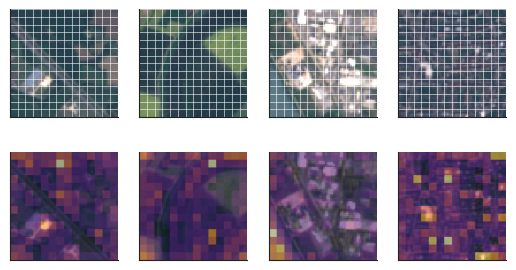

In [3]:
RES = REPO + 'lectures/L14/results/'
import torchvision
root = os.path.join(REPO, 'data', 'raw', 'vision') if os.path.isdir(os.path.join(REPO, 'data')) else 'vision'
os.makedirs(root, exist_ok=True)
ES = torchvision.datasets.EuroSAT(root, download=True)
import torch
from PIL import Image
from transformers import CLIPModel, CLIPProcessor
m = CLIPModel.from_pretrained('openai/clip-vit-base-patch16', attn_implementation='eager').eval()
pr = CLIPProcessor.from_pretrained('openai/clip-vit-base-patch16')
Z = pd.read_csv(RES + 'eurosat_zeroshot.csv')
idx = [int(Z['index'][np.where(Z['true'] == c)[0][3]]) for c in ('Highway', 'River', 'Industrial', 'Residential')]
show('vit.layers', 'transformer layers', len(m.vision_model.encoder.layers))
show('vit.heads', 'attention heads', int(m.config.vision_config.num_attention_heads))
fig, axs = plt.subplots(2, 4, figsize=(6.4, 3.4))
for c, i in enumerate(idx):
    img = ES[i][0]
    with torch.no_grad():
        out = m.vision_model(pixel_values=pr(images=[img], return_tensors='pt')['pixel_values'], output_attentions=True)
    R = torch.eye(197)
    for A in out.attentions:
        A = A.mean(1)[0] + torch.eye(197)
        R = (A / A.sum(-1, keepdim=True)) @ R
    att = R[0, 1:].reshape(14, 14).numpy()
    big = np.asarray(img.resize((224, 224), Image.NEAREST))
    axs[0, c].imshow(big)
    for g in range(0, 225, 16):
        axs[0, c].axhline(g - 0.5, color='white', lw=0.4); axs[0, c].axvline(g - 0.5, color='white', lw=0.4)
    axs[1, c].imshow(big)
    axs[1, c].imshow(np.kron(att, np.ones((16, 16))), cmap='inferno', alpha=0.55)
    for a in axs[:, c]:
        a.set_xticks([]); a.set_yticks([])
fig.savefig('vit_patches_attention.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()